In [19]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from keras._tf_keras.keras.applications import EfficientNetB0
from keras._tf_keras.keras.models import Model
from keras._tf_keras.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from keras._tf_keras.keras.optimizers import AdamW
from keras._tf_keras.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
from keras._tf_keras.keras.callbacks import LearningRateScheduler

In [20]:
# Paths to balanced dataset
data_dir = r"C:\Users\Legion\Desktop\pneumo\data\balanced"

In [21]:
# Model Parameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 40 #Change epochs as needed

In [22]:
# Data Augmentation for Dynamic Augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2
)
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255)

In [23]:
# Data Generators
train_generator = train_datagen.flow_from_directory(
    os.path.join(data_dir, 'train'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)
val_generator = val_test_datagen.flow_from_directory(
    os.path.join(data_dir, 'val'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)
test_generator = val_test_datagen.flow_from_directory(
    os.path.join(data_dir, 'test'),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 5982 images belonging to 2 classes.
Found 1282 images belonging to 2 classes.
Found 1282 images belonging to 2 classes.


In [24]:
# Compute class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(enumerate(class_weights))

In [25]:
# Load ResNet50 Model
base_model = EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

In [26]:
# Freeze the base layers
for layer in base_model.layers[:-30]: # was 10 before
    layer.trainable = False

In [27]:
# Add custom layers
global_avg_pooling = GlobalAveragePooling2D()(base_model.output)
dense_layer = Dense(128, activation='relu')(global_avg_pooling)  # Extra dense layer
dropout_layer = Dropout(0.3)(global_avg_pooling) # was 0.3 before
prediction_layer = Dense(len(train_generator.class_indices), activation='softmax')(dropout_layer)

In [28]:
# Compile Model
model = Model(inputs=base_model.input, outputs=prediction_layer)
optimizer = AdamW(learning_rate=1e-5, weight_decay=1e-5) # was 1e-4 before in both !
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_2 (Rescaling)       │ (None, 224, 224, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ normalization_1               │ (None, 224, 224, 3)       │               7 │ rescaling_2[0][0]          │
│ (Normalization)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_3 (Rescaling)       │ (None, 224, 224, 3)       │               0 │ normalization_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv_pad (ZeroPadding2D) │ (None, 225, 225, 3)       │               0 │ rescaling_3[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv (Conv2D)            │ (None, 112, 112, 32)      │             864 │ stem_conv_pad[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_bn (BatchNormalization)  │ (None, 112, 112, 32)      │             128 │ stem_conv[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_activation (Activation)  │ (None, 112, 112, 32)      │               0 │ stem_bn[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_dwconv                │ (None, 112, 112, 32)      │             288 │ stem_activation[0][0]      │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_bn                    │ (None, 112, 112, 32)      │             128 │ block1a_dwconv[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_activation            │ (None, 112, 112, 32)      │               0 │ block1a_bn[0][0]           │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_squeeze            │ (None, 32)                │               0 │ block1a_activation[0][0]   │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reshape (Reshape)  │ (None, 1, 1, 32)          │               0 │ block1a_se_squeeze[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reduce (Conv2D)    │ (None, 1, 1, 8)           │             264 │ block1a_se_reshape[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_expand (Conv2D)    │ (None, 1, 1, 32)          │             28

 Total params: 4,052,133 (15.46 MB)

 Trainable params: 1,498,722 (5.72 MB)

 Non-trainable params: 2,553,411 (9.74 MB)

In [29]:
# Cyclic Learning Rate Scheduler
def lr_schedule(epoch, lr):
    if epoch < 10:
        return 1e-4
    elif epoch < 20:
        return 5e-5
    else:
        return 1e-5
lr_scheduler = LearningRateScheduler(lr_schedule)

In [30]:
# Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
    lr_scheduler
]

In [31]:
# Train Model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    steps_per_epoch=len(train_generator),
    validation_steps=len(val_generator),
    callbacks=callbacks
)

C:\Users\Legion\.pyenv\pyenv-win\versions\3.10.11\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 164s 824ms/step - accuracy: 0.6069 - loss: 0.6554 - val_accuracy: 0.5055 - val_loss: 0.6836 - learning_rate: 1.0000e-04
Epoch 2/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 150s 804ms/step - accuracy: 0.6754 - loss: 0.5754 - val_accuracy: 0.7340 - val_loss: 0.5516 - learning_rate: 1.0000e-04
Epoch 3/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 150s 804ms/step - accuracy: 0.7103 - loss: 0.5391 - val_accuracy: 0.7902 - val_loss: 0.4443 - learning_rate: 1.0000e-04
Epoch 4/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 151s 805ms/step - accuracy: 0.7144 - loss: 0.5300 - val_accuracy: 0.7223 - val_loss: 0.5630 - learning_rate: 1.0000e-04
Epoch 5/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 150s 803ms/step - accuracy: 0.7162 - loss: 0.5250 - val_accuracy: 0.7285 - val_loss: 0.5443 - learning_rate: 1.0000e-04
Epoch 6/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 150s 804ms/step - accuracy: 0.7408 - loss: 0.4896 - val_accuracy: 0.7668 - val_loss: 0.4222 - learning_rate: 1.0000e-04
Epoch 7/40
187/187 ━━━━━━━━━━━━━━━━━━━━ 

In [32]:
# Evaluate Model
print("Evaluating model on test set...")
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test Accuracy: {test_accuracy:.2f}")

Evaluating model on test set...
41/41 ━━━━━━━━━━━━━━━━━━━━ 18s 441ms/step - accuracy: 0.8311 - loss: 0.3218
Test Accuracy: 0.85


In [33]:
# Classification Report and Confusion Matrix
y_pred = model.predict(test_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_generator.classes

print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=list(test_generator.class_indices.keys())))

41/41 ━━━━━━━━━━━━━━━━━━━━ 21s 483ms/step
Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.87      0.84      0.85       645
   PNEUMONIA       0.84      0.87      0.85       637

    accuracy                           0.85      1282
   macro avg       0.85      0.85      0.85      1282
weighted avg       0.85      0.85      0.85      1282



In [34]:
# F1 Score
f1 = f1_score(y_true, y_pred_classes, average='weighted')
print(f"Weighted F1-Score: {f1:.2f}")

Weighted F1-Score: 0.85


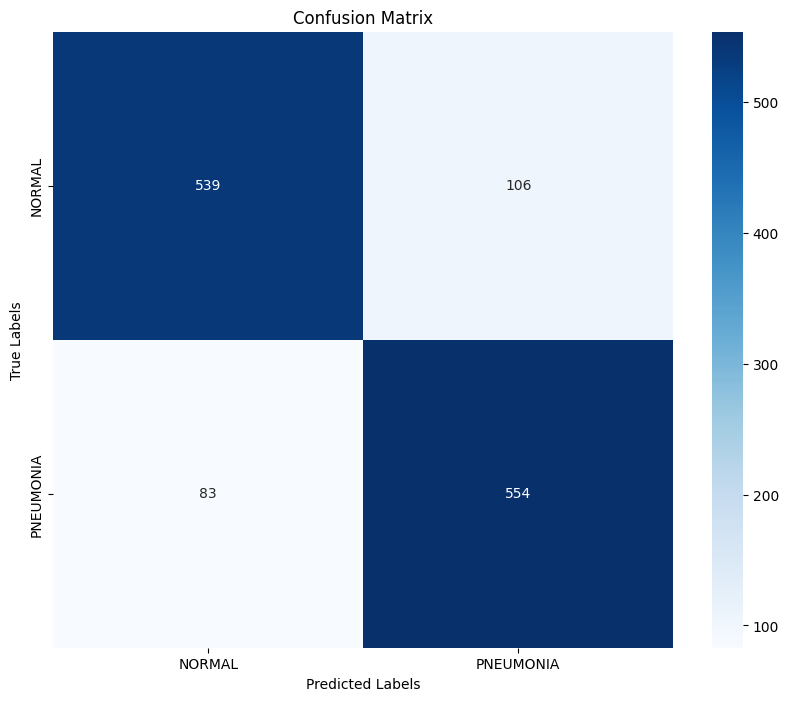

In [35]:
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [36]:
# Save Model
model.save(r'C:\Users\Legion\Desktop\pneumo\efficent_net\Model\Effiecent_net_Pneumo2.keras')
print("Model saved as 'Effiecent_net_Pneumo2.keras'")

Model saved as 'Effiecent_net_Pneumo2.keras'


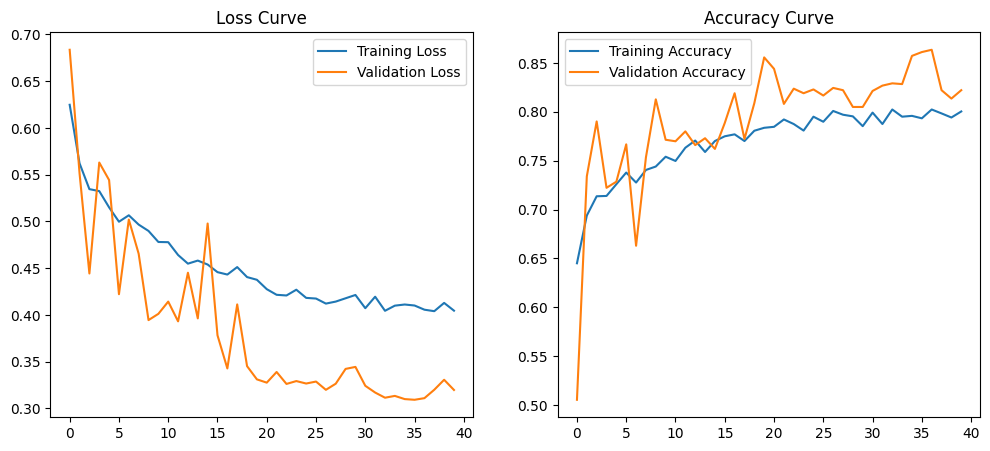

In [37]:
# Plot Training History
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.show()